# Import libraries

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import os,joblib

from sklearn.preprocessing import OneHotEncoder,LabelEncoder,StandardScaler,OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import chi2,f_classif
#from imblearn.over_sampling import SMOTE


from sklearn.metrics import f1_score,confusion_matrix,classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb



# Read Data

In [2]:
data_path=os.path.join(os.getcwd(),'..','dataset','churn-data.csv')
df=pd.read_csv(data_path)
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'],inplace=True)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  object 
 2   Gender           10000 non-null  object 
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), object(2)
memory usage: 859.5+ KB


In [5]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


# EDA

In [6]:
df.isna().sum()

CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [7]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [8]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

# Data Vizulaization 


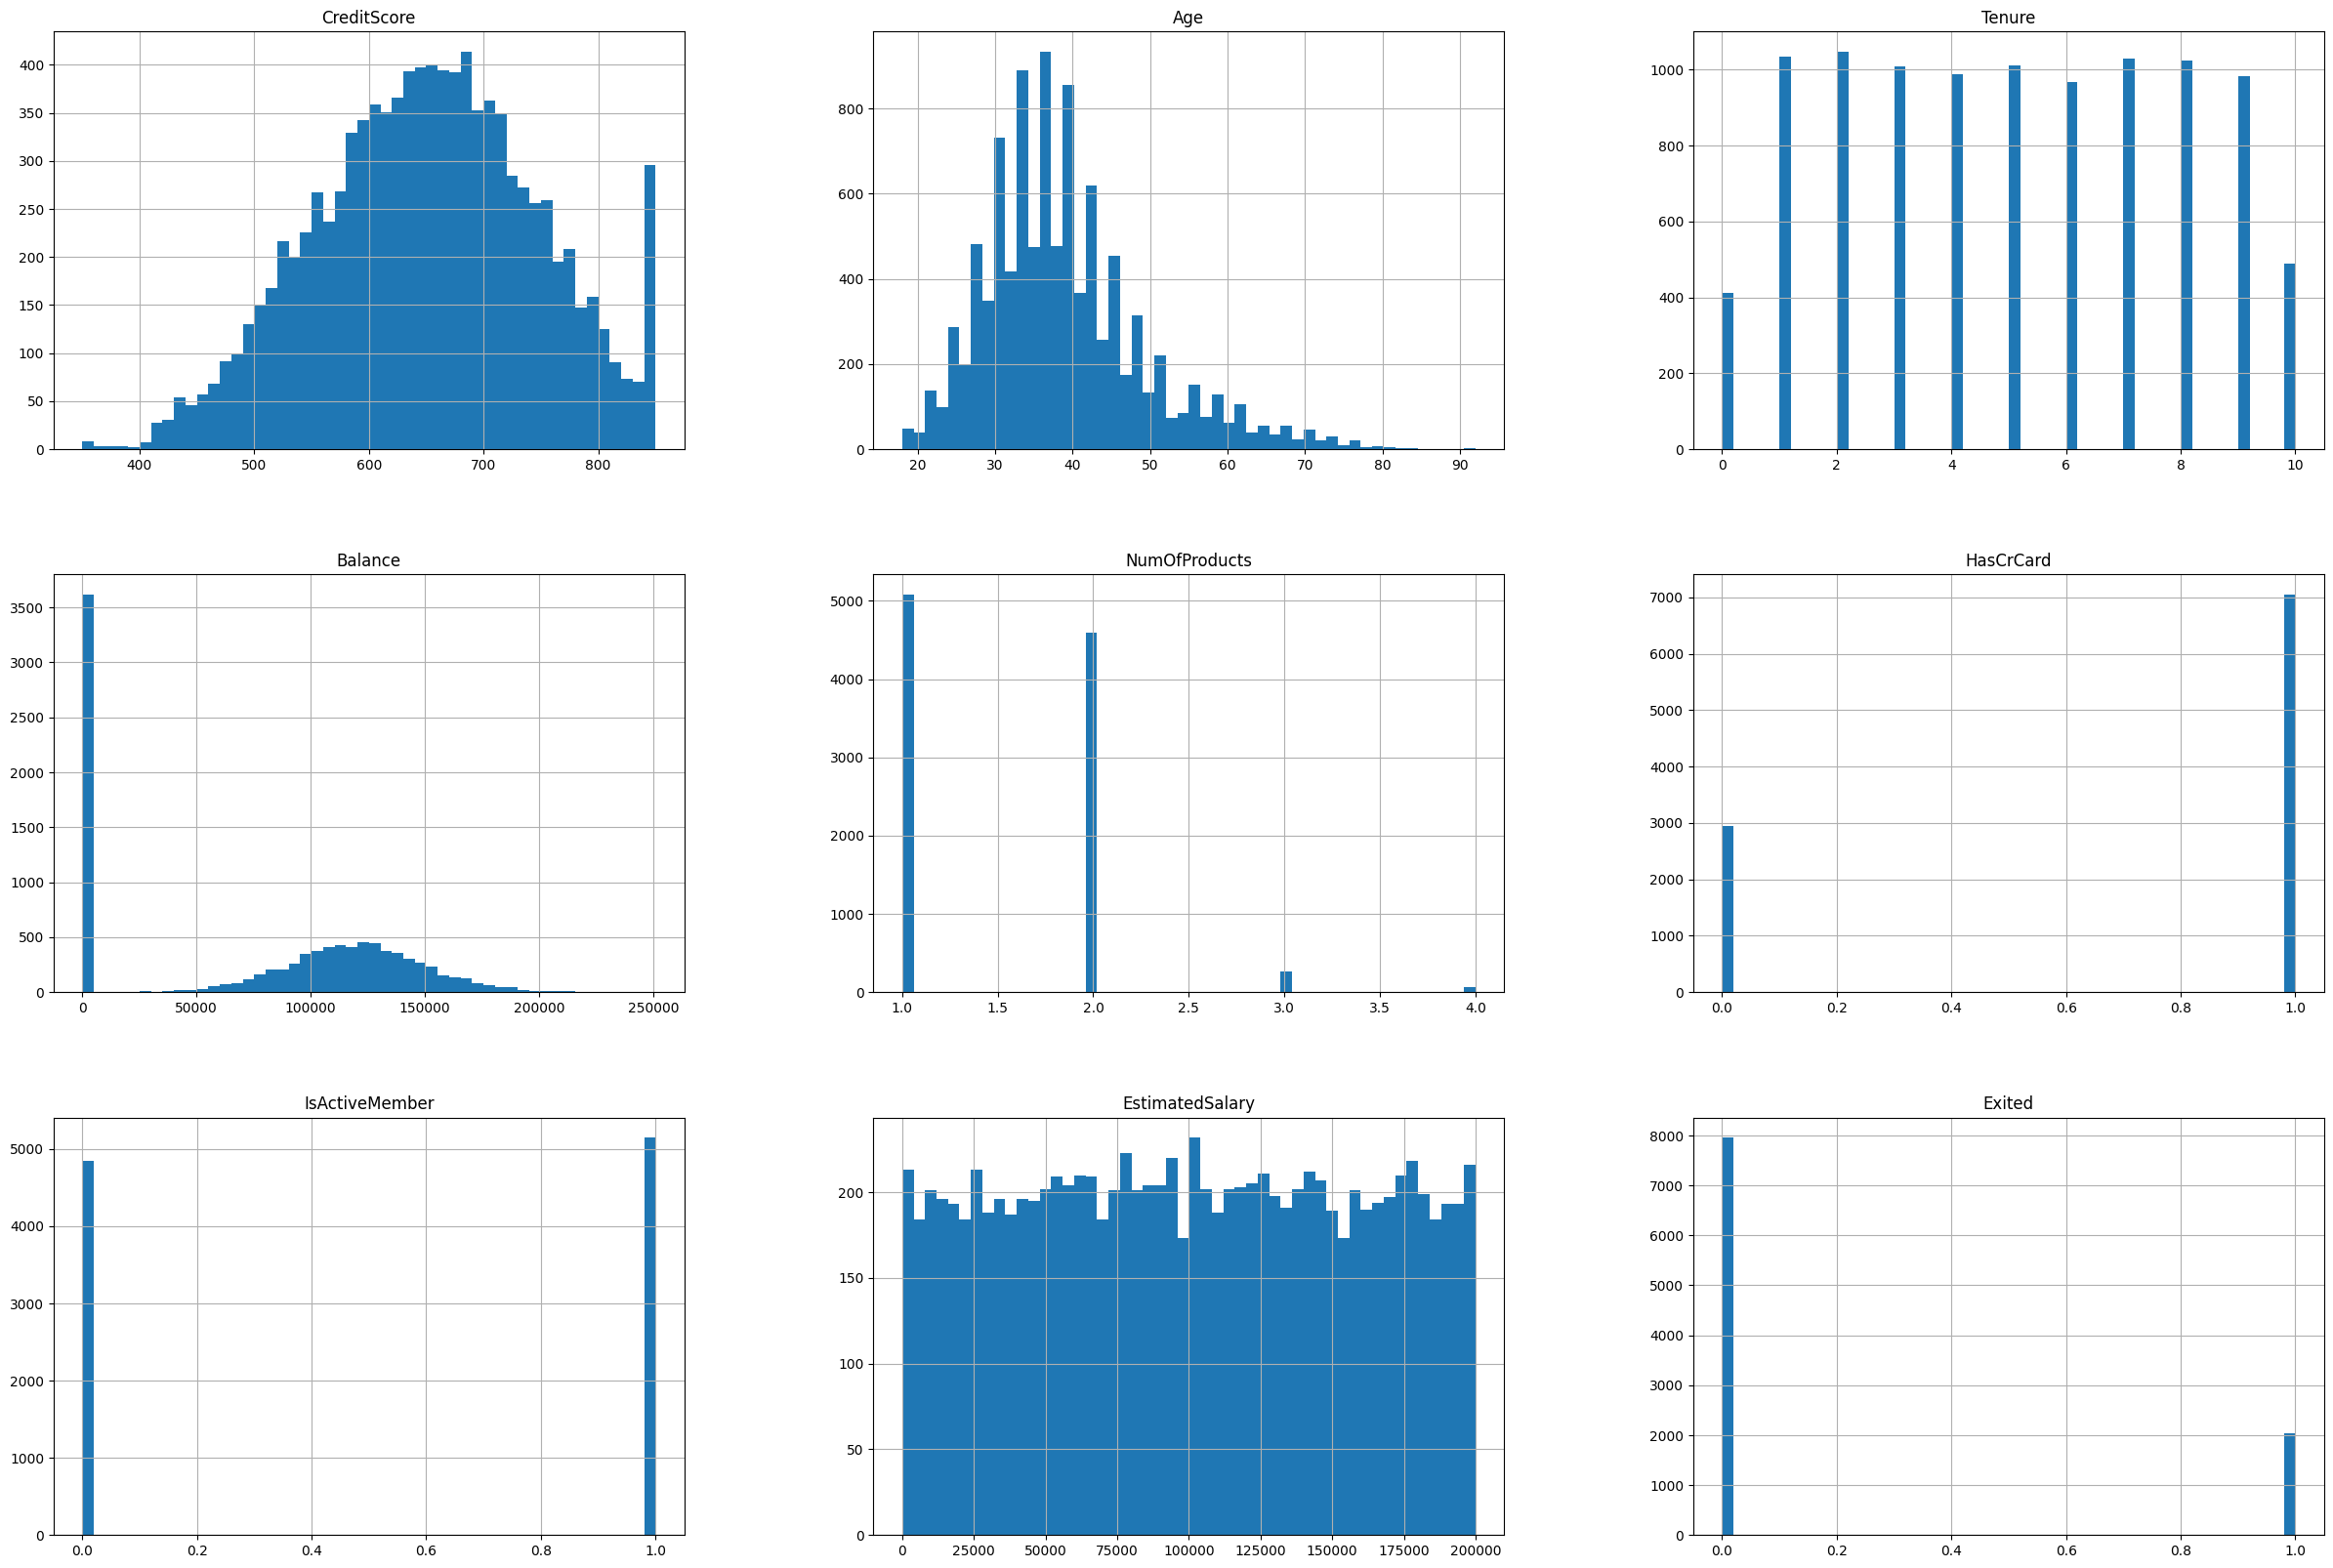

In [9]:
df.hist(bins=50,figsize=(30,20))
plt.show()

<Axes: ylabel='Age'>

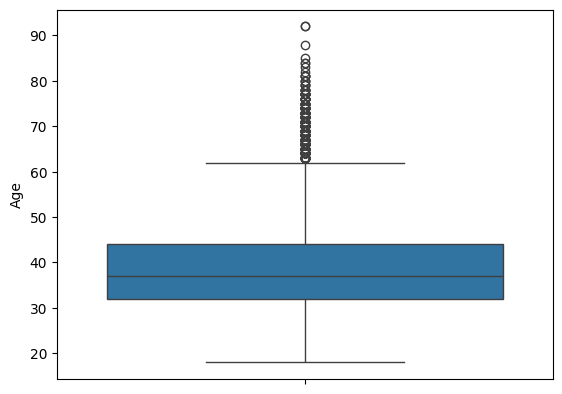

In [10]:
sns.boxplot(data=df,y='Age')

<Axes: ylabel='CreditScore'>

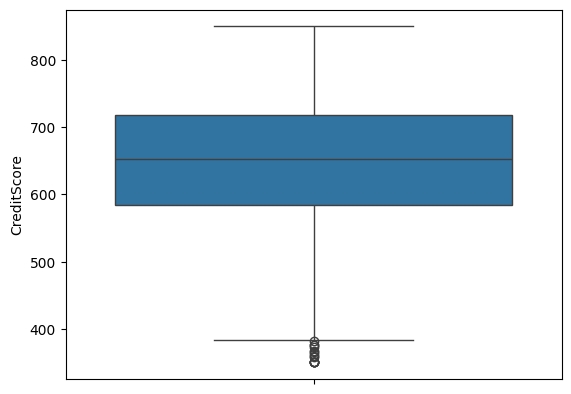

In [11]:
sns.boxplot(data=df,y='CreditScore')

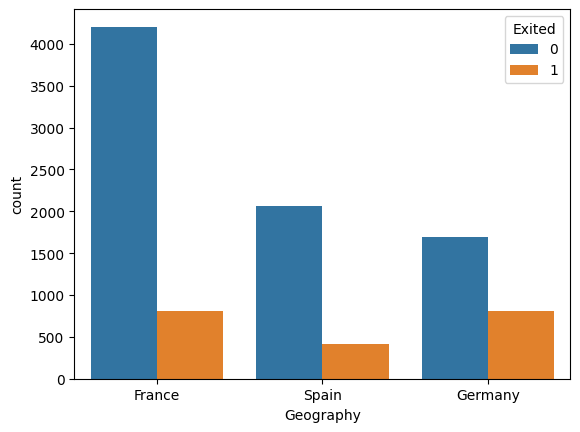

In [12]:
# countplot
sns.countplot(data=df, x='Geography',hue='Exited')  
plt.show()

<Axes: xlabel='Gender', ylabel='count'>

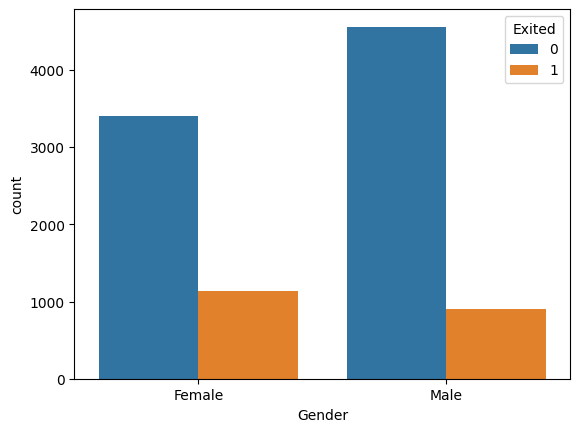

In [13]:
sns.countplot(data=df,x='Gender',hue='Exited')

<Axes: xlabel='HasCrCard', ylabel='count'>

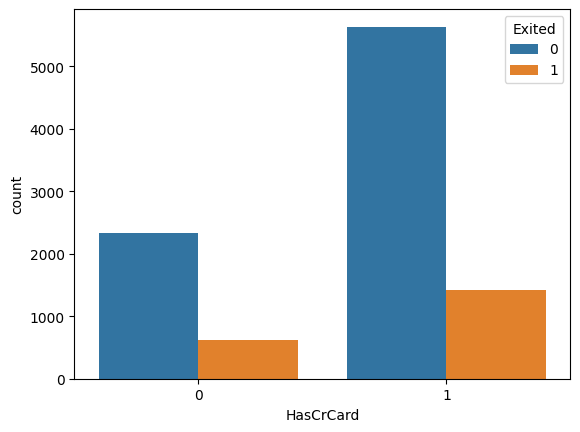

In [14]:
sns.countplot(data=df,x='HasCrCard',hue='Exited')

<Axes: xlabel='NumOfProducts', ylabel='count'>

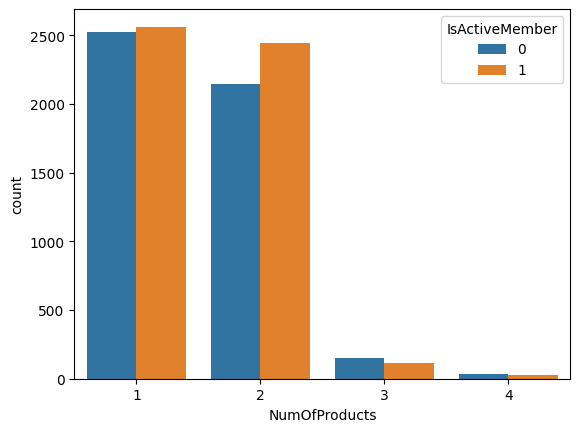

In [15]:
sns.countplot(data=df,x='NumOfProducts',hue='IsActiveMember')

In [16]:
## Averge salary per Gender
df.groupby('Gender')['EstimatedSalary'].mean()

Gender
Female    100601.541382
Male       99664.576931
Name: EstimatedSalary, dtype: float64

<Axes: xlabel='Gender', ylabel='EstimatedSalary'>

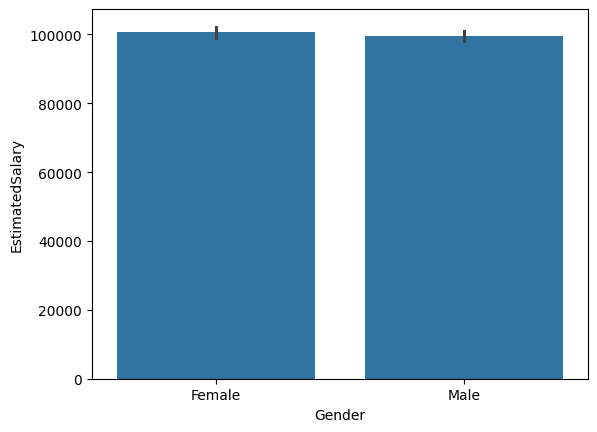

In [17]:
sns.barplot(data=df, y='EstimatedSalary', x='Gender', estimator='mean')

# Split and Preprossing Data

In [18]:
X=df.drop(columns=['Exited'])
y=df['Exited']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=45, stratify=y)
# Check shapes
print('X_train.shape \t', X_train.shape)
print('y_train.shape \t', y_train.shape)
print('***'*10)
print('X_test.shape \t', X_test.shape)
print('y_test.shape \t', y_test.shape)

X_train.shape 	 (8000, 10)
y_train.shape 	 (8000,)
******************************
X_test.shape 	 (2000, 10)
y_test.shape 	 (2000,)


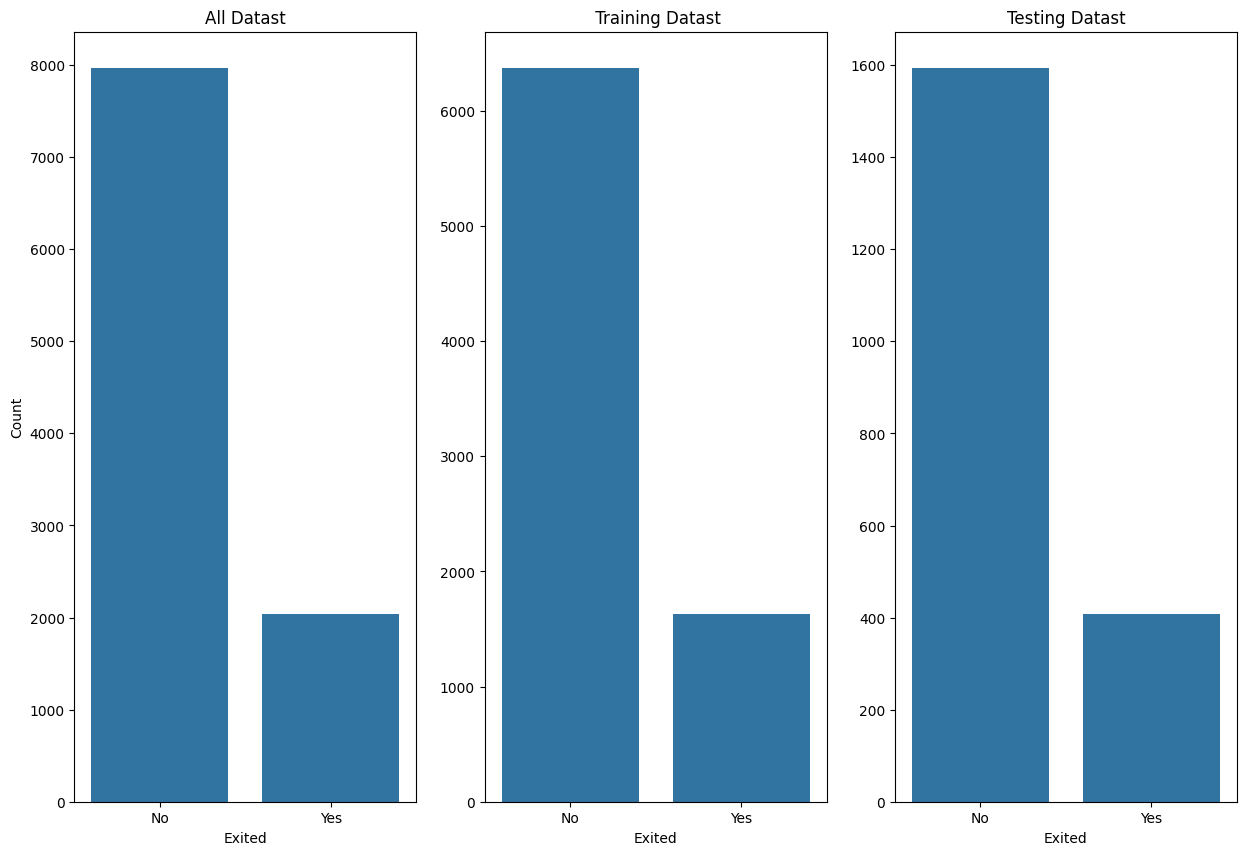

In [19]:
#plotting to check size of Exited

fig,ax=plt.subplots(1,3,figsize=(15,10))

plt.sca(ax[0])
sns.countplot(x=y)
plt.title('All Datast')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['No', 'Yes'])

plt.sca(ax[1])
sns.countplot(x=y_train)
plt.title(' Training Datast')
plt.ylabel('')
plt.xticks(ticks=[0, 1], labels=['No', 'Yes'])


plt.sca(ax[2])
sns.countplot(x=y_test)
plt.title('Testing Datast')
plt.ylabel('')
plt.xticks(ticks=[0, 1], labels=['No', 'Yes'])
plt.show()


* `Feature Selection & Preporcessing`

In [ ]:
num_col=['CreditScore', 'Age', 'Balance', 'EstimatedSalary']
categ_col=['Gender', 'Geography']

other_col=[c for c in X_train.columns if c not in num_col+categ_col]


In [21]:
# Numerical cols  & Target cols (category) --> ANOVA
_,p_value=f_classif(X=X_train[num_col],y=y_train)
p_value # NOTE: CreditScore (~0.10) and EstimatedSalary (~0.38) have p-value > 0.05 (weak/no association); kept as-is


array([9.93415956e-002, 4.53937410e-151, 4.93061528e-027, 3.77885631e-001])

In [22]:
# Categorical cols & Target cols (category)--> chi2
_,p_value=chi2(X=OrdinalEncoder().fit_transform(X_train[categ_col]),y=y_train)
p_value

array([2.10648846e-11, 1.19256538e-03])

In [23]:
# Ready cols (ready_cols) & Target cols --> chi2
_, p_val = chi2(X=X_train[other_col], y=y_train)
p_val  # NOTE: not all p-values are < 0.05 (some features show weak association); kept as-is

array([6.52077590e-02, 1.37949728e-01, 9.69193084e-01, 2.05442478e-21])

In [24]:

num_pipline=Pipeline(
    [
        ('imputer',SimpleImputer(strategy='median')),
        ('Scalar',StandardScaler())
    ]
)

categ_pipline=Pipeline(
    [
        ('imputer',SimpleImputer(strategy='most_frequent')),
        ('ohe',OneHotEncoder(sparse_output=False,drop='first'))
    ]
)

other_pipline=Pipeline(
    [
        ('imputer',SimpleImputer(strategy='most_frequent'))
    ]
)

preprocessor = ColumnTransformer(transformers=[
    ('numerical', num_pipline, num_col),
    ('categorical', categ_pipline, categ_col),
    ('ready', other_pipline, other_col)
])

X_train_final = preprocessor.fit_transform(X_train)
X_test_final = preprocessor.transform(X_test)

* `Solving imbalance dataset`

In [25]:
'''
# 1. prepare class_weights for solving imbalance dataset
vals_count = 1 - (np.bincount(y_train) / len(y_train))
vals_count = vals_count / sum(vals_count)

dict_weights = {}
for i in range(2):  # 2 classes (0, 1)
    dict_weights[i] = vals_count[i]

# to model
dict_weights
'''

'\n# 1. prepare class_weights for solving imbalance dataset\nvals_count = 1 - (np.bincount(y_train) / len(y_train))\nvals_count = vals_count / sum(vals_count)\n\ndict_weights = {}\nfor i in range(2):  # 2 classes (0, 1)\n    dict_weights[i] = vals_count[i]\n\n# to model\ndict_weights\n'

In [26]:
'''
#طريقة ذكية لزيادة عينات الفئة الأقل (الـ 20%)، لكنها لا تكرر الصفوف القديمة، بل تخترع وتولّد عينات جديدة تماماً تشبه العينات

# 2. Using SMOTE for over sampling
over=SMOTE(k_neighbors=5,sampling_strategy=0.7,random_state=42)
X_train_final_resampled, y_train_resampled = over.fit_resample(X_train_final, y_train)

'''

#هستخدم في الموديل ""  weight='balance'  ""

'\n#طريقة ذكية لزيادة عينات الفئة الأقل (الـ 20%)، لكنها لا تكرر الصفوف القديمة، بل تخترع وتولّد عينات جديدة تماماً تشبه العينات\n\n# 2. Using SMOTE for over sampling\nover=SMOTE(k_neighbors=5,sampling_strategy=0.7,random_state=42)\nX_train_final_resampled, y_train_resampled = over.fit_resample(X_train_final, y_train)\n\n'

In [27]:
# Create fodler for the models
MODEL_FOLDER_PATH=os.path.join(os.getcwd(),'..','model')
os.makedirs(MODEL_FOLDER_PATH, exist_ok=True)


In [28]:
# dump the preprocessor
joblib.dump(preprocessor, os.path.join(MODEL_FOLDER_PATH, 'preprocessor.pkl'))

['c:\\Users\\hp\\Documents\\Churn_Project_\\notebook\\..\\model\\preprocessor.pkl']

# Building Models

In [ ]:
# XGBoost had no imbalance handling -> scale_pos_weight = neg/pos (consistent with class_weight='balanced')
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

base_models={
    'LogisticRegression':LogisticRegression(class_weight='balanced',max_iter=100,random_state=45),
    'Random Forest':RandomForestClassifier(class_weight='balanced',n_estimators=200, max_depth=6, min_samples_leaf=20,
            n_jobs=-1, random_state=42),
    'XGBoost':xgb.XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.7, min_child_weight=20,
            reg_lambda=20, scale_pos_weight=scale_pos, n_jobs=-1, random_state=42),
}


In [30]:
rows = []
fitted = {}

for name, model in base_models.items():
    pipeline = Pipeline([('prep', preprocessor), ('model', model)])

    # FIX: fit the full pipeline on RAW data so the stored pipeline is actually fitted end-to-end
    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline

    pred_train = pipeline.predict(X_train)
    pred_test = pipeline.predict(X_test)

    rows.append({
        "Model": name,
        "Train F1-Score": f1_score(y_train, pred_train),
        "Test F1-Score": f1_score(y_test, pred_test),
    })

    print(f"\n[+] Classification Report for Model: {name}")
    print(classification_report(y_test, pred_test))
    print("-" * 50)

print("\n======= Baseline Models Comparison Summary =======")
results = pd.DataFrame(rows).set_index("Model")
print(results.to_string(float_format="{:.3f}".format))



[+] Classification Report for Model: LogisticRegression
              precision    recall  f1-score   support

           0       0.90      0.68      0.78      1593
           1       0.36      0.71      0.48       407

    accuracy                           0.69      2000
   macro avg       0.63      0.70      0.63      2000
weighted avg       0.79      0.69      0.72      2000

--------------------------------------------------

[+] Classification Report for Model: Random Forest
              precision    recall  f1-score   support

           0       0.92      0.81      0.86      1593
           1       0.50      0.72      0.59       407

    accuracy                           0.80      2000
   macro avg       0.71      0.77      0.73      2000
weighted avg       0.83      0.80      0.81      2000

--------------------------------------------------

[+] Classification Report for Model: XGBoost
              precision    recall  f1-score   support

           0       0.93      0.80 

# Hyperparameter Tuning (GridSearchCV)

In [35]:
from sklearn.model_selection import StratifiedKFold,GridSearchCV,cross_val_predict
from sklearn.base import clone

cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=45)
def make_pip(model):
    return Pipeline(
        [
            ('prep',preprocessor),
            ('model',model)
        ]
    )

In [36]:
xgb_base=dict(n_jobs=1, random_state=42) 
g1=GridSearchCV(
    make_pip(xgb.XGBClassifier(n_estimators=300, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7, reg_lambda=5, **xgb_base)),
    param_grid={
        'model__max_depth':[3,4,5,6],
        'model__min_child_weight':[1,5],
        'model__scale_pos_weigh':[1, np.sqrt(scale_pos), scale_pos]
        },
    scoring='average_precision',cv=cv,n_jobs=-1
        
).fit(X_train,y_train)

p1=g1.best_params_
print("Stage 1 Best Params:", p1)
print(f"Stage 1 Best Score: {g1.best_score_:.4f}")

###
g2=GridSearchCV(
    make_pip(xgb.XGBClassifier(n_estimators=300, learning_rate=0.03,**p1,**xgb_base)),
    param_grid={
        'model__subsample':[0.6,0.8,0.9],
        'model__colsample_bytree':[0.6,0.8,0.9]},
    scoring='average_precision',cv=cv,n_jobs=-1
    ).fit(X_train,y_train)

p2=g2.best_params_
print("Stage 2 Best Params:", p2)
print(f"Stage 2 Best Score: {g2.best_score_:.4f}")

###
g3=GridSearchCV(
    make_pip(xgb.XGBClassifier(**p1,**p2,**xgb_base)),
    param_grid={
        'model__learning_rate': [0.01, 0.02, 0.03],
        'model__n_estimators': [300, 500, 800]},
    scoring='average_precision', cv=cv, n_jobs=-1
).fit(X_train, y_train)

print('Stage 3 (Final XGBoost Params):', g3.best_params_, "Score:", round(g3.best_score_, 4))
xgb_search = g3





c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:48:49] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "scale_pos_weigh" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Stage 1 Best Params: {'model__max_depth': 5, 'model__min_child_weight': 1, 'model__scale_pos_weigh': 1}
Stage 1 Best Score: 0.7076


c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:49:00] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "model__max_depth", "model__min_child_weight", "model__scale_pos_weigh" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Stage 2 Best Params: {'model__colsample_bytree': 0.6, 'model__subsample': 0.9}
Stage 2 Best Score: 0.7076


c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:49:17] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "model__colsample_bytree", "model__max_depth", "model__min_child_weight", "model__scale_pos_weigh", "model__subsample" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Stage 3 (Final XGBoost Params): {'model__learning_rate': 0.02, 'model__n_estimators': 300} Score: 0.7027


# Final Model Evaluation

In [37]:

rf_search = GridSearchCV(
 make_pip(RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=1, random_state=42)),
    param_grid={'model__max_depth': [6, 8, 10], 'model__min_samples_leaf': [10, 20]},
    scoring='average_precision', cv=cv, n_jobs=-1).fit(X_train, y_train)


lr_search = GridSearchCV(
    make_pip(LogisticRegression(class_weight='balanced', max_iter=1000, random_state=45)),
    param_grid={'model__C': [0.01, 0.1, 1, 10]},
    scoring='average_precision', cv=cv, n_jobs=-1).fit(X_train, y_train)



searches = {'LogisticRegression': lr_search, 'Random Forest': rf_search, 'XGBoost': xgb_search
}

thresholds=np.arange(0.05,0.9,.01)

# Lists to store the final metrics for the comparison summary table
model_names = []
cv_ap_scores = []
best_thresholds = []
oof_f1_scores = []
test_f1_default = []
test_f1_tuned = []


for name,search_object in searches.items():
    best_model=search_object.best_estimator_
    
    oof_probabilities = cross_val_predict(clone(best_model),
                                          X_train, y_train, cv=cv, method='predict_proba')[:, 1]
    
    #  Calculate F1-Score for every threshold to find the highest one
    f1_score_list=[]
    for t in thresholds:
        current_prediction=(oof_probabilities>=t).astype(int)
        current_f1=f1_score(y_train,current_prediction)
        f1_score_list.append(current_f1)
        
    # find the threshold that gave the maximum F1-Score
    best_index=np.argmax(f1_score_list)
    optimal_thresold=thresholds[best_index]
    max_oof_f1=f1_score_list[best_index]
    
    #  Evaluate on the unseen Test Data
    test_probabilities = best_model.predict_proba(X_test)[:, 1]
    
    f1_at_05 = f1_score(y_test, test_probabilities >= 0.50)
    f1_at_tuned = f1_score(y_test, test_probabilities >= optimal_thresold)
    
    # Save all calculated scores to our tracking lists
    model_names.append(name)
    cv_ap_scores.append(search_object.best_score_)
    best_thresholds.append(optimal_thresold)
    oof_f1_scores.append(max_oof_f1)
    test_f1_default.append(f1_at_05)
    test_f1_tuned.append(f1_at_tuned)
    
    summary_df = pd.DataFrame({
    'Model': model_names,
    'CV AP (PR-AUC)': cv_ap_scores,
    'Best Threshold': best_thresholds,
    'OOF F1 (Train)': oof_f1_scores,
    'Test F1 @0.50': test_f1_default,
    'Test F1 @tuned_thr': test_f1_tuned
}).set_index("Model")

print("\n======= Comprehensive Threshold Tuning Summary =======")
print(summary_df.to_string(float_format="{:.3f}".format))

        
    




c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [01:52:56] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "model__colsample_bytree", "model__max_depth", "model__min_child_weight", "model__scale_pos_weigh", "model__subsample" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [01:52:57] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "model__colsample_bytree", "model__max_depth", "model__min_child_weight", "model__scale_pos_weigh", "model__subsample" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [01:52:58] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "model__colsample_bytree", "mod


======= Comprehensive Threshold Tuning Summary =======
                    CV AP (PR-AUC)  Best Threshold  OOF F1 (Train)  Test F1 @0.50  Test F1 @tuned_thr
Model                                                                                                
LogisticRegression           0.460           0.510           0.504          0.481               0.486
Random Forest                0.683           0.560           0.630          0.604               0.617
XGBoost                      0.703           0.340           0.627          0.565               0.616


In [38]:

final_model = xgb_search.best_estimator_

train_probabilities = final_model.predict_proba(X_train)[:, 1]
test_probabilities = final_model.predict_proba(X_test)[:, 1]

best_threshold = 0.34

y_pred_train = (train_probabilities >= best_threshold).astype(int)
y_pred_test = (test_probabilities >= best_threshold).astype(int)

print("======= XGBoost Final Performance =======")
print(f"Decision Threshold Used: {best_threshold}")
print(f"Train F1-Score: {f1_score(y_train, y_pred_train):.3f}")
print(f"Test F1-Score : {f1_score(y_test, y_pred_test):.3f}\n")

print("======= Detailed Classification Report (Test Set) =======")
print(classification_report(y_test, y_pred_test, target_names=['Stayed (0)', 'Churned (1)']))

print("======= Confusion Matrix =======")
print(confusion_matrix(y_test, y_pred_test))


======= XGBoost Final Performance =======
Decision Threshold Used: 0.34
Train F1-Score: 0.701
Test F1-Score : 0.616

======= Detailed Classification Report (Test Set) =======
              precision    recall  f1-score   support

  Stayed (0)       0.90      0.91      0.90      1593
 Churned (1)       0.63      0.60      0.62       407

    accuracy                           0.85      2000
   macro avg       0.76      0.76      0.76      2000
weighted avg       0.84      0.85      0.85      2000

======= Confusion Matrix =======
[[1449  144]
 [ 162  245]]


In [40]:
# Save the full pipeline (preprocessor + model) together with the tuned decision threshold
joblib.dump({'pipeline': final_model, 'threshold': final_model}, os.path.join(MODEL_FOLDER_PATH, 'final_model.pkl'))

['c:\\Users\\hp\\Documents\\Churn_Project_\\notebook\\..\\model\\final_model.pkl']